# EDA · Real Food Classifier · Análisis

Continuación de `01_eda.ipynb`. Partimos del dataset limpio (`data/processed/off_nova_clean.csv.gz`, 48.119 productos) y analizamos cómo se relaciona cada variable con la clase NOVA.

**Todo el análisis se hace solo con train.** El test se reserva para evaluar los modelos: si lo miramos ahora para tomar decisiones (transformaciones, variables), la métrica final saldría optimista.

## Paso 9 · Carga y comprobación del split

Cargamos el CSV limpio, separamos train y comprobamos que el split fijo conserva la proporción de clases.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path("../data/processed/off_nova_clean.csv.gz")
df = pd.read_csv(DATA, dtype={"code": str})

print(df["split"].value_counts())
train = df[df["split"] == "train"].copy()

split
train    38495
test      9624
Name: count, dtype: int64


In [2]:
# Si StratifiedGroupKFold funcionó, las dos columnas deberían ser casi iguales
pd.crosstab(df["nova_group"], df["split"], normalize="columns").round(3)

split,test,train
nova_group,,
1,0.129,0.129
2,0.112,0.112
3,0.204,0.204
4,0.555,0.555


### 9.1 Resultados

- Train: 38.495 productos (80 %) · Test: 9.624 (20 %).
- Las proporciones de NOVA son **idénticas** en train y test (12,9 / 11,2 / 20,4 / 55,5 %): el `StratifiedGroupKFold` estratifica bien aunque agrupe por producto.

Agrupamos las columnas por tipo para usarlas en el resto del análisis: 9 nutrientes por 100 g, 14 marcadores `tiene_*` (10 de ultraprocesado, 3 de ingredientes culinarios añadidos y 1 de conservantes) y 2 niveles de categoría.

In [3]:
OBJETIVO = "nova_group"
NO_MODELO = ["code", "product_name", "brands", "grupo_producto", "ingredients_text", "split"]

nutrientes  = [c for c in df.columns if c.endswith("_100g")]   # se buscan por sufijo, sin escribirlos a mano
marcadores  = [c for c in df.columns if c.startswith("tiene_")]
anadidos = ["tiene_sal", "tiene_azucar", "tiene_aceite"]                          # ingredientes culinarios (NOVA 3)
ultra = [c for c in marcadores if c not in anadidos + ["tiene_conservantes"]]    # los 10 de ultraprocesado
print(len(ultra), "de ultraprocesado ·", len(anadidos), "añadidos · conservantes")
categoricas = ["pnns_groups_1", "pnns_groups_2"]
print(len(nutrientes), nutrientes)
print(len(marcadores), marcadores)

10 de ultraprocesado · 3 añadidos · conservantes
9 ['energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'fruits-vegetables-legumes_100g']
14 ['tiene_aromas', 'tiene_edulcorantes', 'tiene_jarabes', 'tiene_almidon_modificado', 'tiene_grasa_hidrogenada', 'tiene_proteina_aislada', 'tiene_colorantes', 'tiene_emulsionantes', 'tiene_potenciadores', 'tiene_aceite_palma', 'tiene_conservantes', 'tiene_sal', 'tiene_azucar', 'tiene_aceite']


## Paso 10 · Categoría del producto

`pnns_groups_1` (11 categorías + unknown) y `pnns_groups_2` (41 subcategorías + unknown) clasifican el producto por tipo de alimento. Miramos cómo se reparte NOVA dentro de cada categoría y decidimos qué nivel entra al modelo.

### 10.1 NOVA por categoría (`pnns_groups_1`)

pnns_groups_1
Sugary snacks              7396
unknown                    5293
Fat and sauces             4911
Cereals and potatoes       4822
Milk and dairy products    3739
Beverages                  3696
Fish Meat Eggs             2785
Fruits and vegetables      2330
Salty snacks               1665
Composite foods            1444
Alcoholic beverages         290
Baby foods                  124
Name: count, dtype: int64

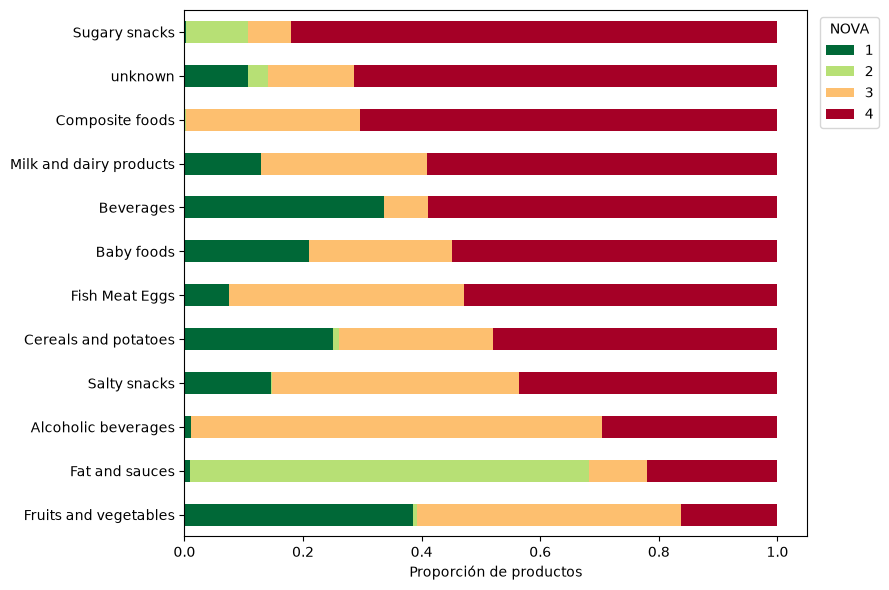

In [4]:
tabla = pd.crosstab(train["pnns_groups_1"], train[OBJETIVO], normalize="index")
orden = tabla[4].sort_values().index        # ordenadas por % de ultraprocesados

ax = tabla.loc[orden].plot(kind="barh", stacked=True, figsize=(9, 6), colormap="RdYlGn_r")
ax.set_xlabel("Proporción de productos")
ax.set_ylabel("")
ax.legend(title="NOVA", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()

train["pnns_groups_1"].value_counts()       # el tamaño de cada categoría importa: un 100 % sobre 12 productos no dice mucho

| Categoría | Productos | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|---|
| Fruits and vegetables | 2.330 | 39 % | 1 % | 44 % | 16 % |
| Fat and sauces | 4.911 | 1 % | 67 % | 10 % | 22 % |
| Alcoholic beverages | 290 | 1 % | 0 % | 69 % | 30 % |
| Salty snacks | 1.665 | 15 % | 0 % | 42 % | 44 % |
| Cereals and potatoes | 4.822 | 25 % | 1 % | 26 % | 48 % |
| Fish Meat Eggs | 2.785 | 8 % | 0 % | 40 % | 53 % |
| Baby foods | 124 | 21 % | 0 % | 24 % | 55 % |
| Beverages | 3.696 | 34 % | 0 % | 8 % | 59 % |
| Milk and dairy products | 3.739 | 13 % | 0 % | 28 % | 59 % |
| Composite foods | 1.444 | 0 % | 0 % | 29 % | 70 % |
| unknown | 5.293 | 11 % | 3 % | 15 % | 71 % |
| Sugary snacks | 7.396 | 0 % | 10 % | 7 % | 82 % |

**Conclusiones:**
- **La clase 2 está casi toda en `Fat and sauces`** (aceites, mantequilla, vinagres) y en menor medida en `Sugary snacks` (azúcar, miel). En el resto de categorías es prácticamente 0. La categoría será clave para reconocer la clase 2.
- **`Sugary snacks` (82 %) y `Composite foods` (70 %)** son mayoritariamente ultraprocesados. `Composite foods` no tiene ningún NOVA 1.
- **`unknown` no es neutra:** tiene un 71 % de NOVA 4, por encima de la media (55,5 %). Confirma que conviene mantenerla como categoría propia y no imputarla.
- **Categorías mezcladas:** en `Fruits and vegetables` (fresco frente a conserva), `Salty snacks` (frutos secos frente a patatas fritas) y `Cereals and potatoes` la categoría sola no basta. Ahí tendrán que trabajar los ingredientes y los nutrientes.
- Todas las categorías tienen tamaño suficiente; la más pequeña es `Baby foods`, con 124 productos en train. A este nivel no hay categorías raras.

### 10.2 NOVA por subcategoría (`pnns_groups_2`)

Cada subcategoría pertenece a una sola categoría de nivel 1. Miramos si el nivel 2 separa mejor las clases y cuántas subcategorías tienen muy pocos productos.

In [5]:
# Comprobación: si sale 1, cada subcategoría está dentro de una única categoría de nivel 1
print(train.groupby("pnns_groups_2")["pnns_groups_1"].nunique().max())

# % de cada clase dentro de cada subcategoría, agrupado por su categoría de nivel 1
tabla2 = pd.crosstab([train["pnns_groups_1"], train["pnns_groups_2"]], train[OBJETIVO], normalize="index")
tabla2["n"] = train.groupby(["pnns_groups_1", "pnns_groups_2"]).size()
tabla2.round(2)

1


nova_group                                                   1     2     3  \
pnns_groups_1           pnns_groups_2                                        
Alcoholic beverages     Alcoholic beverages               0.01  0.00  0.69   
Baby foods              Baby foods                        0.27  0.00  0.31   
                        Baby milks                        0.00  0.00  0.00   
Beverages               Artificially sweetened beverages  0.00  0.00  0.00   
                        Fruit juices                      0.87  0.00  0.01   
                        Fruit nectars                     0.34  0.00  0.00   
                        Plant-based milk substitutes      0.09  0.00  0.17   
                        Sweetened beverages               0.01  0.00  0.19   
                        Teas and herbal teas and coffees  0.64  0.00  0.07   
                        Unsweetened beverages             0.46  0.00  0.07   
                        Waters and flavored waters        0.97  0.00  0.00   
Cereals and potatoes    Bread                             0.01  0.00  0.35   
                        Breakfast cereals                 0.13  0.00  0.21   
                        Cereals                           0.54  0.03  0.12   
                        Legumes                           0.35  0.00  0.46   
                        Potatoes                          0.03  0.00  0.40   
Composite foods         One-dish meals                    0.00  0.00  0.37   
                        Pizza pies and quiches            0.00  0.00  0.14   
                        Sandwiches                        0.00  0.00  0.09   
Fat and sauces          Dressings and sauces              0.03  0.18  0.27   
                        Fats                              0.00  0.96  0.00   
Fish Meat Eggs          Eggs                              0.90  0.00  0.07   
                        Fish and seafood                  0.08  0.00  0.69   
                        Meat                              0.07  0.00  0.16   
                        Offals                            0.00  0.00  0.80   
                        Processed meat                    0.00  0.00  0.19   
Fruits and vegetables   Dried fruits                      0.34  0.00  0.49   
                        Fruits                            0.66  0.03  0.14   
                        Soups                             0.00  0.00  0.65   
                        Vegetables                        0.40  0.00  0.48   
Milk and dairy products Cheese                            0.00  0.00  0.64   
                        Dairy desserts                    0.03  0.00  0.07   
                        Ice cream                         0.00  0.00  0.01   
                        Milk and yogurt                   0.33  0.00  0.10   
Salty snacks            Appetizers                        0.00  0.00  0.38   
                        Nuts                              0.47  0.00  0.36   
                        Salty and fatty products          0.03  0.00  0.52   
Sugary snacks           Biscuits and cakes                0.00  0.00  0.07   
                        Chocolate products                0.00  0.00  0.12   
                        Pastries                          0.00  0.00  0.07   
                        Sweets                            0.01  0.22  0.05   
unknown                 unknown                           0.11  0.03  0.15   

nova_group                                                   4     n  
pnns_groups_1           pnns_groups_2                                 
Alcoholic beverages     Alcoholic beverages               0.30   290  
Baby foods              Baby foods                        0.43    98  
                        Baby milks                        1.00    26  
Beverages               Artificially sweetened beverages  1.00   886  
                        Fruit juices                      0.12   384  
                        Fruit nectars                     0.66    35  

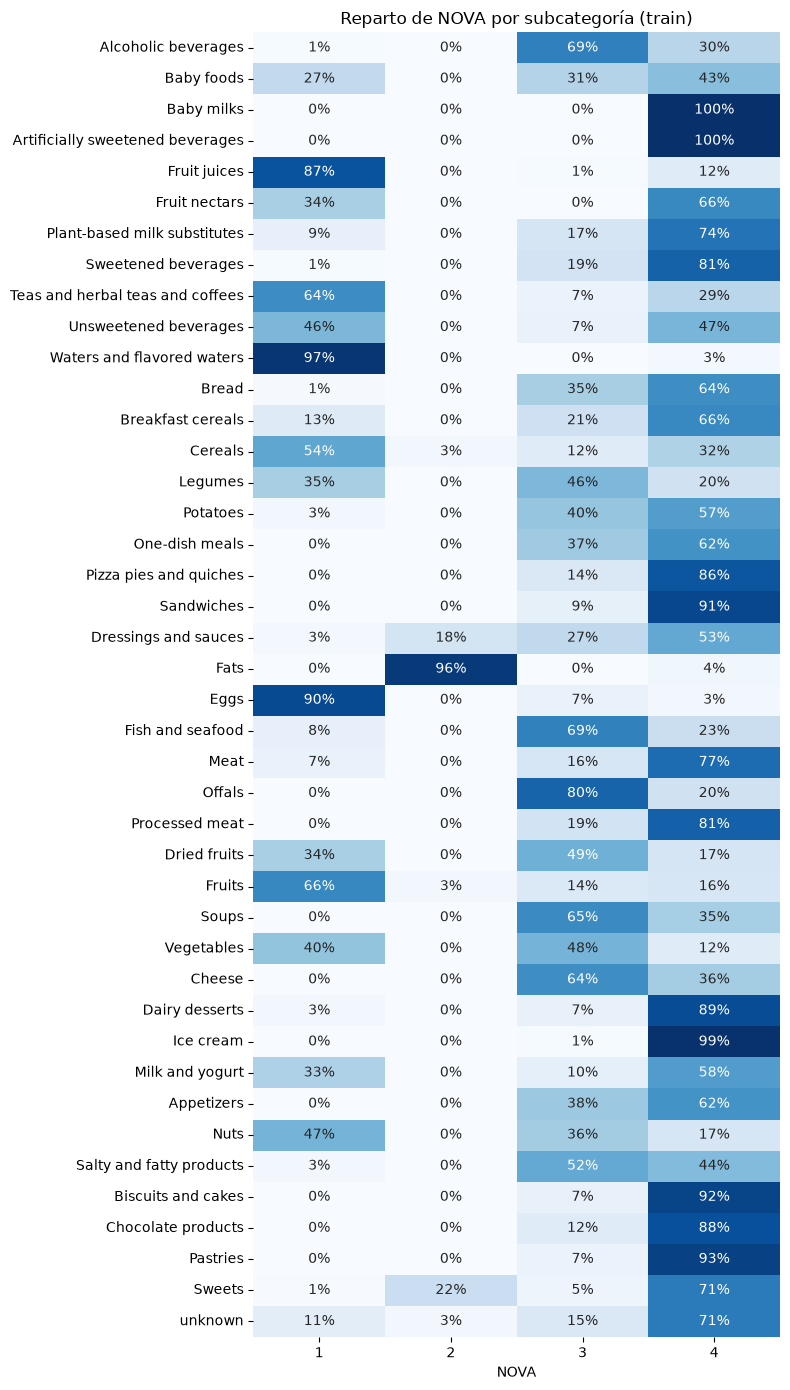

In [6]:
# 42 filas: un heatmap se lee mejor que 42 barras apiladas
fig, ax = plt.subplots(figsize=(8, 14))
sns.heatmap(
    tabla2[[1, 2, 3, 4]].droplevel(0),   # quitamos el nivel 1 de las etiquetas para que no sean tan largas
    annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax
)
ax.set_xlabel("NOVA")
ax.set_ylabel("")
ax.set_title("Reparto de NOVA por subcategoría (train)")
plt.tight_layout()

In [7]:
conteo2 = train["pnns_groups_2"].value_counts()

# Probamos varios umbrales para ver cuántas subcategorías y productos quedarían como "raros"
for umbral in [30, 50, 100]:
    raras = conteo2[conteo2 < umbral]
    print(f"< {umbral}: {len(raras)} subcategorías, {raras.sum()} productos")

conteo2[conteo2 < 100]

< 30: 2 subcategorías, 41 productos
< 50: 3 subcategorías, 76 productos
< 100: 5 subcategorías, 243 productos


pnns_groups_2
Baby foods       98
Eggs             69
Fruit nectars    35
Baby milks       26
Offals           15
Name: count, dtype: int64

**Resultados:**
- El nivel 2 está **anidado** en el nivel 1: cada subcategoría pertenece a una sola categoría.
- **Separa mucho mejor las clases** que el nivel 1. Algunos ejemplos:
  - `Fat and sauces` mezclaba dos cosas: `Fats` es 96 % NOVA 2 y `Dressings and sauces` es 53 % NOVA 4.
  - En `Beverages`: `Waters and flavored waters` es 97 % NOVA 1, `Fruit juices` 87 % NOVA 1 y `Artificially sweetened beverages` 100 % NOVA 4.
  - En `Fish Meat Eggs`: `Eggs` es 90 % NOVA 1, `Fish and seafood` 69 % NOVA 3 y `Processed meat` 81 % NOVA 4.
- Siguen mezcladas: `Cereals` (54 % NOVA 1 / 32 % NOVA 4), `Legumes`, `Vegetables`, `Dried fruits`, `Nuts` y `Milk and yogurt` (fresco frente a preparado). Ahí decidirán los ingredientes.
- La clase 2 está en `Fats` (96 %: aceites y mantequillas), `Sweets` (22 %: miel y azúcar) y `Dressings and sauces` (18 %: casi todo vinagres). En `unknown`, `Cereals` y `Fruits` es residual.

**Subcategorías raras** (train):

| Umbral | Subcategorías | Productos |
|---|---|---|
| < 30 | 2 (`Offals` 15, `Baby milks` 26) | 41 |
| < 50 | 3 (+ `Fruit nectars` 35) | 76 |
| < 100 | 5 (+ `Eggs` 69, `Baby foods` 98) | 243 |

Son muy pocas y suman menos del 0,7 % del train.

### 10.3 Decisiones (propuesta para el equipo)

- **Entra al modelo `pnns_groups_2`** (41 subcategorías + `unknown`) porque es más informativa. `pnns_groups_1` es redundante (anidada) y no hace falta. Si se usaran las dos en la regresión logística, las variables estarían duplicadas.
- **Subcategorías raras:** no se tocan en el CSV. En la fase 2 se agrupan dentro del pipeline con `OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist")`, que calcula la frecuencia solo con train y manda a la categoría "infrecuente" cualquier subcategoría nueva que aparezca en test o en la app.
- **App:** elegir entre 41 subcategorías en un formulario es incómodo. Gemini puede proponerla a partir de la foto, y la usuaria la confirma en un desplegable.

## Paso 11 · Nutrientes por clase

NOVA no clasifica por composición nutricional, pero la composición puede ayudar a distinguir clases, sobre todo la 1, la 2 y la 3, donde los marcadores de ultraprocesado no aparecen. Usamos la **mediana** porque los nutrientes tienen colas largas (aceites, sal, azúcar).

### 11.1 Medianas y distribución

In [8]:
# Mediana de cada nutriente por clase (filas = nutrientes, columnas = NOVA)
medianas = train.groupby(OBJETIVO)[nutrientes].median().T.round(1)
medianas

nova_group,1,2,3,4
energy-kcal_100g,75.0,882.0,220.0,273.0
fat_100g,1.0,99.0,8.3,8.2
saturated-fat_100g,0.2,13.0,1.5,2.0
carbohydrates_100g,9.6,0.0,7.0,26.0
sugars_100g,2.8,0.0,1.4,5.6
fiber_100g,2.7,0.0,1.7,1.8
proteins_100g,3.4,0.0,7.5,5.6
salt_100g,0.0,0.0,0.9,0.4
fruits-vegetables-legumes_100g,0.0,0.0,0.0,0.0


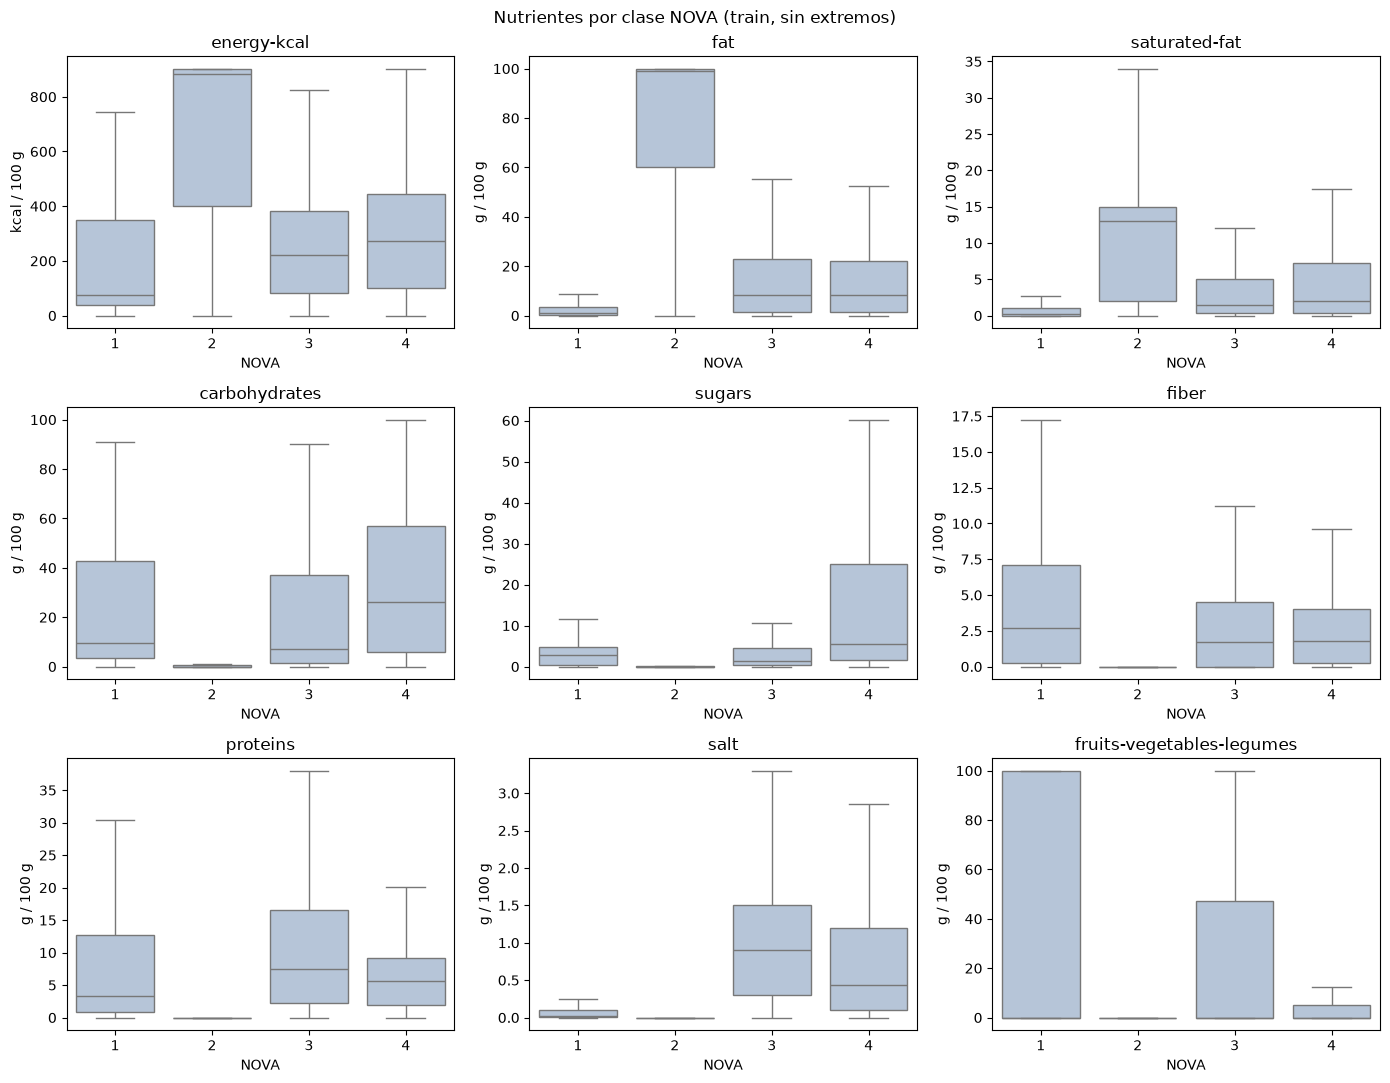

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))

for ax, col in zip(axes.flat, nutrientes):
    # showfliers=False oculta los extremos: con ellos las cajas quedan aplastadas y no se ven las diferencias
    sns.boxplot(data=train, x=OBJETIVO, y=col, showfliers=False, color="lightsteelblue", ax=ax)
    ax.set_title(col.replace("_100g", ""))
    ax.set_xlabel("NOVA")
    ax.set_ylabel("kcal / 100 g" if "energy" in col else "g / 100 g")

plt.suptitle("Nutrientes por clase NOVA (train, sin extremos)")
plt.tight_layout()

**Resultados** (medianas por 100 g, train):

| Nutriente | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|
| Energía (kcal) | 75 | 882 | 220 | 273 |
| Grasa | 1,0 | 99,0 | 8,3 | 8,2 |
| Saturadas | 0,2 | 13,0 | 1,5 | 2,0 |
| Hidratos | 9,6 | 0,0 | 7,0 | 26,0 |
| Azúcares | 2,8 | 0,0 | 1,4 | 5,6 |
| Fibra | 2,7 | 0,0 | 1,7 | 1,8 |
| Proteínas | 3,4 | 0,0 | 7,5 | 5,6 |
| Sal | 0,0 | 0,0 | 0,9 | 0,4 |
| Fruta, verdura y legumbres | 0,0 | 0,0 | 0,0 | 0,0 |

**Conclusiones:**
- **NOVA 2 es inconfundible** por su composición: mediana de 99 g de grasa y 882 kcal (aceites), con hidratos, proteínas y fibra a 0. Junto con `Fats` (paso 10), es la clase más fácil de reconocer.
- **NOVA 1** es lo menos calórico (75 kcal): aguas, frutas, verduras, leche y huevos. Casi sin sal.
- **NOVA 3** tiene la sal más alta (0,9 g): quesos, conservas y embutidos curados. También la proteína más alta (7,5 g).
- **NOVA 4** tiene más hidratos (26 g) y azúcares (5,6 g) que el resto, pero sus cajas se solapan mucho con las de NOVA 3. **Los nutrientes solos no separan 3 y 4**: ahí dependemos de los marcadores y de `n_ingredientes`.
- **Fruta, verdura y legumbres** tiene mediana 0 en todas las clases (el 54 % de los productos tiene 0). Solo aporta información en la cola.

### 11.2 ¿Los nulos dependen de la clase?

Los nulos que quedan se imputan en la fase 2. Antes de elegir cómo, comprobamos si faltan al azar o se concentran en alguna clase.

In [10]:
# % de nulos de cada nutriente dentro de cada clase
nulos_clase = train.groupby(OBJETIVO)[nutrientes].apply(lambda g: g.isna().mean() * 100).T.round(1)
nulos_clase[nulos_clase.max(axis=1) > 5]   # solo los nutrientes con más de un 5 % de nulos en alguna clase

nova_group,1,2,3,4
energy-kcal_100g,1.2,8.0,0.2,0.3
fat_100g,1.9,10.4,1.0,0.9
saturated-fat_100g,4.8,7.6,1.8,2.2
carbohydrates_100g,2.0,10.7,1.1,0.7
sugars_100g,4.3,9.1,1.9,1.5
fiber_100g,14.2,78.1,19.8,34.2
proteins_100g,1.9,11.0,0.8,0.8
salt_100g,1.9,9.2,1.7,2.1
fruits-vegetables-legumes_100g,7.0,85.8,0.7,1.0


In [11]:
# Fruta/verdura/legumbres es una estimación de Open Food Facts a partir de los ingredientes:
# si no hay lista de ingredientes, no se puede calcular
print(pd.crosstab(train["fruits-vegetables-legumes_100g"].isna(), train["sin_lista_ingredientes"]))
print()
print(pd.crosstab(train["fiber_100g"].isna(), train["sin_lista_ingredientes"]))

sin_lista_ingredientes              0     1
fruits-vegetables-legumes_100g             
False                           34181     0
True                              344  3970

sin_lista_ingredientes      0     1
fiber_100g                         
False                   25103   464
True                     9422  3506


**Resultados** (% de nulos por clase, train):

| Nutriente | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|
| Fibra | 14 % | **78 %** | 20 % | 34 % |
| Fruta, verdura y legumbres | 7 % | **86 %** | 1 % | 1 % |

**Los nulos no son aleatorios: se concentran en la clase 2.**
- **Resto de nutrientes:** en las clases 1, 3 y 4 faltan como mucho en un 5 % de los productos, pero en la clase 2 faltan en un 8-11 %. Son productos con la tabla nutricional incompleta, sobre todo mieles (284 de los 473 NOVA 2 sin proteínas).
- **Fruta, verdura y legumbres:** de los 4.314 nulos, 3.970 (92 %) son productos sin lista de ingredientes. Open Food Facts la estima a partir de los ingredientes, así que sin lista no puede calcularla. Este nulo repite la información de `sin_lista_ingredientes`.
- **Fibra:** en la UE es **voluntario** declararla en la tabla nutricional (Reglamento 1169/2011), por eso falta en un 33 % de los productos. Los aceites casi nunca la declaran porque no tienen.

**Implicaciones para la fase 2:**
- Imputar la fibra con la mediana global (1,7 g) daría fibra a los aceites, que no tienen. Opciones: imputar con la mediana **por subcategoría** o usar `SimpleImputer(strategy="median", add_indicator=True)`, que además añade una columna 0/1 "faltaba la fibra". Esa columna aporta información porque los nulos dependen de la clase.
- Fruta, verdura y legumbres: la mediana es 0, así que imputar con la mediana da un valor razonable.
- **App:** como la fibra es voluntaria, en la etiqueta real a veces no aparecerá. El modelo tiene que aceptar ese campo vacío en el formulario, y el pipeline con imputador lo resuelve.

## Paso 12 · Ingredientes, aditivos y marcadores

### 12.1 Variables asimétricas

`n_ingredientes` y `additives_n` cuentan cosas: muchos productos tienen valores bajos y unos pocos llegan a valores muy altos. La sal tiene el mismo problema (la propia sal tiene 100 g). Medimos la asimetría (*skewness*) antes y después de aplicar `log1p` (log(1 + x), que admite ceros).

In [12]:
asimetricas = ["n_ingredientes", "additives_n", "salt_100g"]

# skew ≈ 0: simétrica · > 1: cola larga a la derecha
pd.DataFrame({
    "skew": train[asimetricas].skew(),
    "skew_log1p": np.log1p(train[asimetricas]).skew(),
}).round(1)

,skew,skew_log1p
n_ingredientes,5.0,0.0
additives_n,2.2,0.6
salt_100g,16.3,2.3


In [13]:
# Mediana y P75: con tantos ceros, la mediana sola esconde diferencias (p. ej. en additives_n)
pd.concat(
    {"mediana": train.groupby(OBJETIVO)[asimetricas].median(),
     "p75": train.groupby(OBJETIVO)[asimetricas].quantile(0.75)},
    axis=1,
).round(2)

mediana                                  p75              \
           n_ingredientes additives_n salt_100g n_ingredientes additives_n   
nova_group                                                                   
1                     1.0         0.0      0.02            2.0         0.0   
2                     1.0         0.0      0.00            1.0         0.0   
3                     4.0         0.0      0.90            6.0         1.0   
4                    10.0         3.0      0.44           14.0         5.0   

                      
           salt_100g  
nova_group            
1                0.1  
2                0.0  
3                1.5  
4                1.2

nova_group
1    94.8
2    99.0
3    72.1
4    13.1
Name: additives_n, dtype: float64

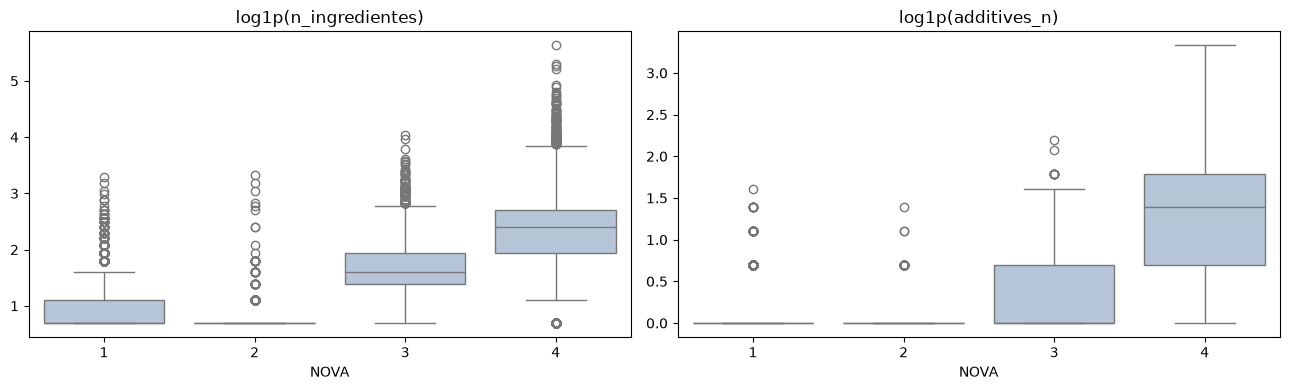

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ["n_ingredientes", "additives_n"]):
    # boxplot de log1p: con la escala original, NOVA 4 aplasta al resto
    sns.boxplot(x=train[OBJETIVO], y=np.log1p(train[col]), color="lightsteelblue", ax=ax)
    ax.set_title(f"log1p({col})")
    ax.set_xlabel("NOVA")
    ax.set_ylabel("")

plt.tight_layout()

# % de productos sin ningún aditivo en cada clase
(train["additives_n"] == 0).groupby(train[OBJETIVO]).mean().mul(100).round(1)

**Resultados** (train):

| Variable | Skew | Skew con log1p | Máximo |
|---|-----|---|---|
| `n_ingredientes` | 5,0 | 0,0 | 279 |
| `additives_n` | 2,2 | 0,6 | 27 |
| `salt_100g` | 16,3 | 2,3 | 100 |

| NOVA | `n_ingredientes` (mediana / P75) | `additives_n` (mediana / P75) | Sin aditivos |
|---|----------------------------------|---|---|
| 1 | 1 / 2                            | 0 / 0 | 95 % |
| 2 | 1 / 1                            | 0 / 0 | 99 % |
| 3 | 4 / 6                            | 0 / 1 | 72 % |
| 4 | 10 / 14                          | 3 / 5 | 13 % |

**Conclusiones:**
- **`n_ingredientes` separa bien 1-2 de 3 y de 4:** los productos sin procesar y los ingredientes culinarios tienen 1 o 2 ingredientes; los procesados, unos 4; y los ultraprocesados, 10 o más.
- **`additives_n`:** el 87 % de los NOVA 4 lleva algún aditivo, frente al 5 % de los NOVA 1. Es una de las variables más claras para separar 4 del resto.
- **`log1p` corrige la asimetría** de `n_ingredientes` (5,0 → 0,0) y `additives_n` (2,2 → 0,6). Con la sal mejora pero sigue siendo asimétrica (2,3), por los productos que son casi sal pura.
- **Fase 2:** aplicar `log1p` a estas tres variables en la regresión logística y en KNN (sensibles a la escala y a los extremos), antes de escalar. Los árboles (Random Forest, XGBoost, LightGBM) no lo necesitan.

### 12.2 Marcadores (`tiene_*`)

En el paso 7 vimos que los marcadores de ultraprocesado aparecen casi solo en NOVA 4 y que los ingredientes culinarios añadidos (sal, azúcar, aceite) aparecen en NOVA 3. Medimos cuánto aparece cada uno por clase y cuántos productos quedan sin explicar.

nova_group,1,2,3,4,total
tiene_sal,0.0,1.7,77.4,57.0,47.6
tiene_azucar,0.0,1.3,23.2,56.4,36.2
tiene_aromas,0.0,0.0,0.0,61.1,33.9
tiene_aceite,0.2,6.6,39.3,39.1,30.5
tiene_emulsionantes,0.0,0.0,0.0,47.1,26.1
tiene_jarabes,0.5,0.2,1.2,34.3,19.4
tiene_conservantes,0.6,0.6,9.5,22.9,14.8
tiene_colorantes,0.0,0.0,0.0,21.1,11.7
tiene_edulcorantes,0.0,0.0,0.0,13.4,7.5
tiene_almidon_modificado,0.0,0.0,0.0,12.8,7.1


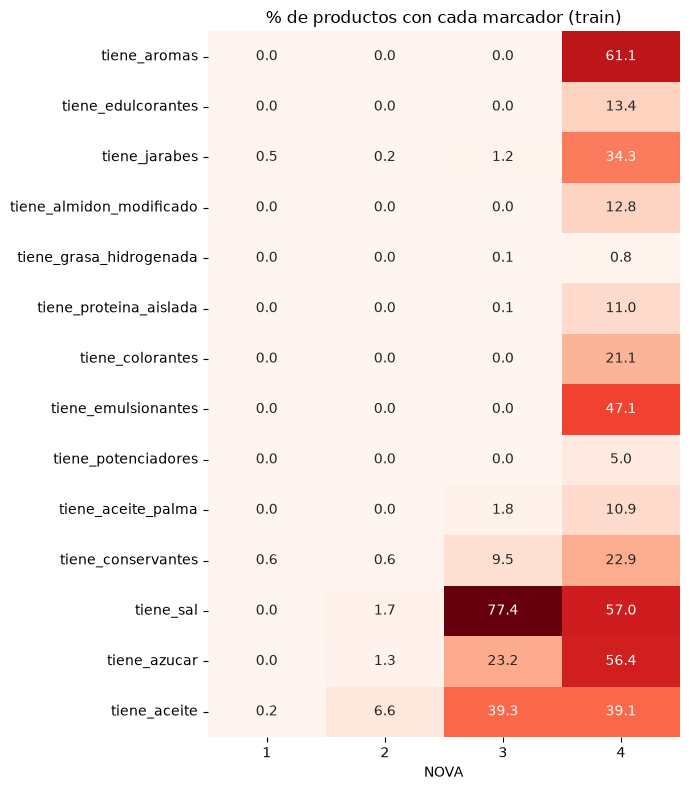

In [15]:
pct_marcadores = (train.groupby(OBJETIVO)[marcadores].mean() * 100).T.round(1)
pct_marcadores["total"] = (train[marcadores].mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(pct_marcadores.drop(columns="total"), annot=True, fmt=".1f", cmap="Reds", cbar=False, ax=ax)
ax.set_xlabel("NOVA")
ax.set_ylabel("")
ax.set_title("% de productos con cada marcador (train)")
plt.tight_layout()

pct_marcadores.sort_values("total", ascending=False)

In [16]:
# Dos grupos: ultraprocesado (casi solo NOVA 4) e ingredientes añadidos (NOVA 3)
ultra_alguno = train[ultra].sum(axis=1) > 0
anadidos_alguno = train[anadidos].sum(axis=1) > 0

print("NOVA 4 sin ningún marcador de ultraprocesado:", f"{(~ultra_alguno[train[OBJETIVO] == 4]).mean():.1%}")
print("NOVA 4 sin ninguno de los 14 marcadores:     ",
      f"{(train.loc[train[OBJETIVO] == 4, marcadores].sum(axis=1) == 0).mean():.1%}")

pd.DataFrame({
    "algún marcador de ultraprocesado (%)": ultra_alguno.groupby(train[OBJETIVO]).mean() * 100,
    "sal, azúcar o aceite (%)": anadidos_alguno.groupby(train[OBJETIVO]).mean() * 100,
}).round(1)

NOVA 4 sin ningún marcador de ultraprocesado: 7.3%
NOVA 4 sin ninguno de los 14 marcadores:      1.3%


,algún marcador de ultraprocesado (%),"sal, azúcar o aceite (%)"
nova_group,,
1,0.6,0.2
2,0.3,9.3
3,3.0,91.1
4,92.7,82.6


**Resultados** (% de productos con el marcador, train):

| Marcador | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|---|---|
| **Ultraprocesado** | | | | |
| Aromas | 0 | 0 | 0 | 61,1 |
| Emulsionantes (E4xx) | 0 | 0 | 0 | 47,1 |
| Jarabes | 0,5 | 0,2 | 1,2 | 34,3 |
| Colorantes (E1xx) | 0 | 0 | 0 | 21,1 |
| Edulcorantes | 0 | 0 | 0 | 13,4 |
| Almidón modificado | 0 | 0 | 0 | 12,8 |
| Proteína aislada | 0 | 0 | 0,1 | 11,0 |
| Aceite de palma | 0 | 0 | 1,8 | 10,9 |
| Potenciadores (E62x-63x) | 0 | 0 | 0 | 5,0 |
| Grasa hidrogenada | 0 | 0 | 0,1 | 0,8 |
| **Ingredientes añadidos y conservantes** | | | | |
| Sal | 0 | 1,7 | 77,4 | 57,0 |
| Azúcar | 0 | 1,3 | 23,2 | 56,4 |
| Aceite | 0,2 | 6,6 | 39,3 | 39,1 |
| Conservantes | 0,6 | 0,6 | 9,5 | 22,9 |

| | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 |
|---|---|---|-------|---|
| Algún marcador de ultraprocesado | 0,6 % | 0,3 % | 3,0 % | 92,7 % |
| Sal, azúcar o aceite | 0,2 % | 9,3 % | 91,1 % | 82,6 % |

**Conclusiones:**
- **Los marcadores de ultraprocesado son casi exclusivos de NOVA 4:** solo el 7,3 % de los NOVA 4 no tiene ninguno, y en las otras clases aparecen como mucho en el 3,0 % de los productos.
- **Los ingredientes añadidos separan 1 de 3:** el 91 % de los NOVA 3 lleva sal, azúcar o aceite, frente al 0,2 % de los NOVA 1. Es coherente con la definición: NOVA 3 = alimento natural + ingredientes culinarios.
- Con los 14 marcadores juntos, solo el 1,3 % de los NOVA 4 no tiene ninguno.
- **La clase 2 sigue sin marcadores propios:** suele ser un solo ingrediente sin lista. La reconocen `sin_lista_ingredientes`, la categoría (`Fats`, `Sweets`) y los nutrientes (paso 11).
- Esto confirma el aviso del paso 7: Open Food Facts asigna NOVA en parte con estas mismas reglas. **Es esperable que el modelo reconozca muy bien NOVA 4 y separe bien 1 y 3.** Hay que mirar el recall por clase, sobre todo de la 2, y no solo el F1 global.
- **Marcadores poco útiles:** `tiene_grasa_hidrogenada` aparece en el 0,5 % de los productos (0,8 % de los NOVA 4) y `tiene_potenciadores` en el 2,8 %. Aportan poco al modelo y, en la app, son dos casillas más del formulario.

**Para decidir en equipo** (lista final de marcadores = casillas del formulario):
- ¿Quitamos `tiene_grasa_hidrogenada`? Desde 2021 la UE limita las grasas trans (Reglamento 2019/649) y casi no aparece en los datos.
- ¿Mantenemos `tiene_potenciadores`? Es raro, pero cuando aparece (glutamato) es muy claro.

## Paso 13 · Correlaciones

Usamos la correlación de **Spearman**, que trabaja con rangos: no le afectan los extremos ni la asimetría, y detecta relaciones monótonas aunque no sean lineales.

Buscamos dos cosas:
- **Variables redundantes entre sí** (|r| ≥ 0,6): pueden dar problemas en la regresión logística (colinealidad) y pesar el doble en las distancias de KNN.
- **Relación de cada variable con NOVA**, con cuidado: NOVA es ordinal, pero la relación con la clase no tiene por qué ser monótona.

### 13.1 Correlación entre variables

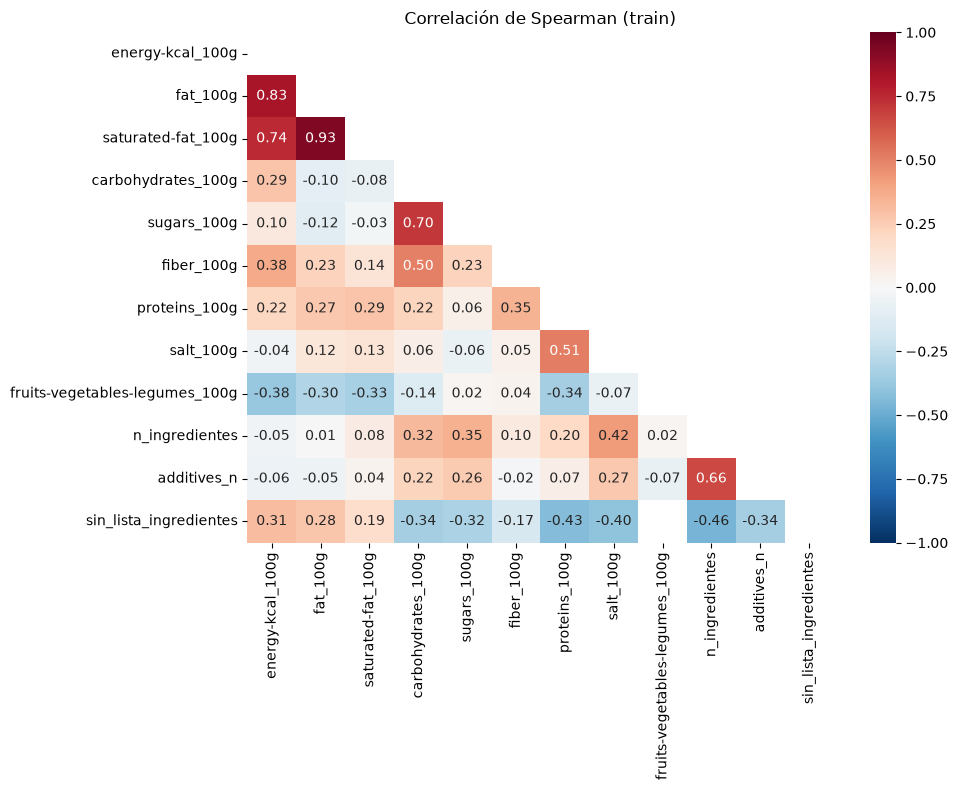

In [17]:
numericas = nutrientes + ["n_ingredientes", "additives_n", "sin_lista_ingredientes"]
corr = train[numericas].corr(method="spearman")

# Máscara del triángulo superior: la matriz es simétrica, así se lee la mitad
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman (train)")
plt.tight_layout()

In [18]:
corr_todas = train[numericas + marcadores].corr(method="spearman")

# Nos quedamos con cada pareja una sola vez (triángulo superior, sin la diagonal)
parejas = corr_todas.where(np.triu(np.ones_like(corr_todas, dtype=bool), k=1)).stack()
parejas[parejas.abs() >= 0.6].sort_values(key=abs, ascending=False).round(2)

fat_100g            saturated-fat_100g     0.93
energy-kcal_100g    fat_100g               0.83
                    saturated-fat_100g     0.74
salt_100g           tiene_sal              0.72
carbohydrates_100g  sugars_100g            0.70
n_ingredientes      additives_n            0.66
additives_n         tiene_emulsionantes    0.66
dtype: float64

**Resultados** (|r| ≥ 0,6):

| Pareja | r |
|---|---|
| `fat_100g` · `saturated-fat_100g` | 0,93 |
| `energy-kcal_100g` · `fat_100g` | 0,83 |
| `energy-kcal_100g` · `saturated-fat_100g` | 0,74 |
| `salt_100g` · `tiene_sal` | 0,72 |
| `carbohydrates_100g` · `sugars_100g` | 0,70 |
| `n_ingredientes` · `additives_n` | 0,66 |
| `tiene_emulsionantes` · `additives_n` | 0,66 |

**Conclusiones:**
- **Grasa y saturadas (0,93)** son casi la misma información. Lo mismo pasa con hidratos y azúcares (0,70), aunque en menor grado.
- **La energía es redundante con los macros.** Se calcula a partir de ellos (9·grasa + 4·hidratos + 4·proteína + 2·fibra) y en 840 productos la recalculamos con esa fórmula (paso 5).
- **`tiene_emulsionantes` y `additives_n` (0,66):** los emulsionantes son aditivos, así que esos productos cuentan dos veces: en el marcador y en el número de aditivos.
- **`tiene_sal` y `salt_100g` (0,72):** es lógico, porque los productos con sal añadida tienen más sal. Pero no son lo mismo: el marcador dice si se ha añadido, y el nutriente cuánta hay (el queso o el jamón la llevan de serie).
- Ninguna pareja es una copia exacta (r = 1), así que **no eliminamos variables en el CSV**.

**Para la fase 2:**
- **Árboles:** no les afecta la colinealidad. Se usan todas.
- **Regresión logística:** con regularización (L2, la de por defecto en scikit-learn) la colinealidad no rompe el modelo, pero los coeficientes de las variables correlacionadas no se pueden interpretar por separado. Opción: probar a quitar `energy-kcal_100g` y `saturated-fat_100g` y comparar el F1 macro.
- **KNN:** las variables redundantes pesan doble en la distancia (la grasa entra dos o tres veces). Conviene probar también sin ellas.

### 13.2 Relación con NOVA

n_ingredientes                    0.75
additives_n                       0.72
tiene_aromas                      0.61
tiene_emulsionantes               0.51
tiene_azucar                      0.49
sin_lista_ingredientes           -0.42
tiene_jarabes                     0.40
sugars_100g                       0.35
salt_100g                         0.35
tiene_sal                         0.34
tiene_colorantes                  0.31
carbohydrates_100g                0.30
tiene_aceite                      0.28
tiene_conservantes                0.27
tiene_edulcorantes                0.24
tiene_almidon_modificado          0.24
tiene_proteina_aislada            0.22
tiene_aceite_palma                0.20
proteins_100g                     0.15
tiene_potenciadores               0.14
fruits-vegetables-legumes_100g   -0.11
saturated-fat_100g                0.09
tiene_grasa_hidrogenada           0.06
energy-kcal_100g                 -0.01
fat_100g                          0.01
fiber_100g               

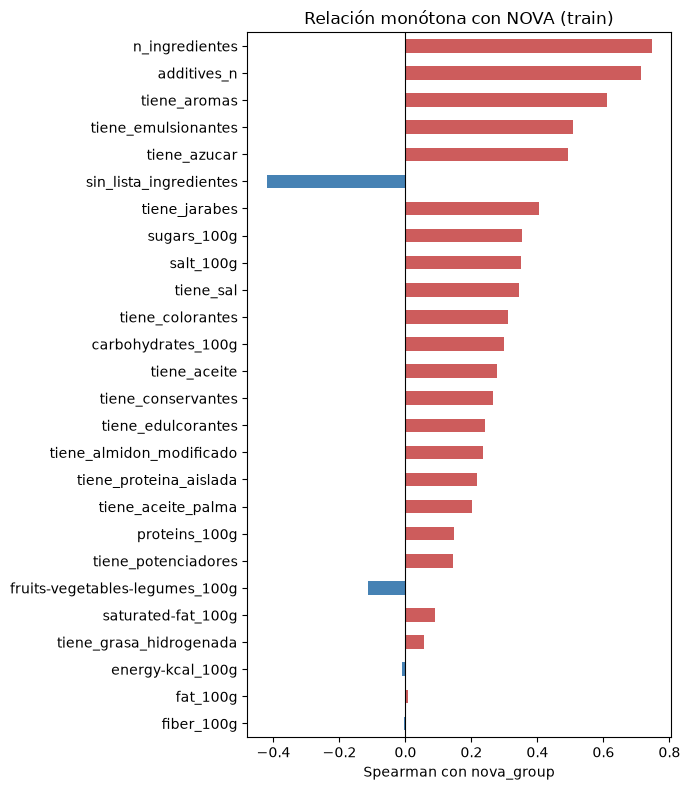

In [19]:
# Spearman con NOVA tratada como ordinal (1 < 2 < 3 < 4)
corr_nova = (
    train[numericas + marcadores + [OBJETIVO]]
    .corr(method="spearman")[OBJETIVO]
    .drop(OBJETIVO)
    .sort_values(key=abs)          # de menor a mayor |r| para que el barh quede con la mayor arriba
)

fig, ax = plt.subplots(figsize=(7, 8))
corr_nova.plot(kind="barh", color=np.where(corr_nova > 0, "indianred", "steelblue"), ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman con nova_group")
ax.set_title("Relación monótona con NOVA (train)")
plt.tight_layout()

corr_nova.sort_values(key=abs, ascending=False).round(2)

**Resultados** (Spearman con `nova_group`, train):

| Variable | r |
|---|---|
| `n_ingredientes` | 0,75 |
| `additives_n` | 0,72 |
| `tiene_aromas` | 0,61 |
| `tiene_emulsionantes` | 0,51 |
| `tiene_azucar` | 0,49 |
| `sin_lista_ingredientes` | −0,42 |
| `tiene_jarabes` | 0,40 |
| `sugars_100g`, `salt_100g` | 0,35 |
| … | |
| `fat_100g` | 0,01 |
| `energy-kcal_100g` | −0,01 |
| `fiber_100g` | 0,00 |

**Conclusiones:**
- Las variables con más relación son las de **ingredientes y aditivos**: `n_ingredientes` (0,75), `additives_n` (0,72) y los marcadores. Coincide con la definición de NOVA (grado de procesamiento, no composición).
- **Una correlación baja no significa que la variable no sirva.** La grasa y la energía tienen r ≈ 0, pero en el paso 11 vimos que **identifican la clase 2** (mediana de 99 g de grasa y 882 kcal). La relación no es monótona: la grasa sube en la clase 2 y vuelve a bajar en la 3 y la 4. Spearman solo mide si la variable sube o baja a la vez que la clase, así que no la detecta.
- Pasa lo mismo con **`tiene_sal`** (0,34): separa muy bien 1 de 3 (0 % frente a 77 %), pero en NOVA 4 baja al 57 %. Como no sube de forma continua con la clase, Spearman no recoge toda su utilidad.
- **No descartamos variables por su correlación con NOVA.** La selección de variables se hace en la fase 2, con la importancia en los modelos y con validación cruzada.

## Paso 14 · Conclusiones del EDA

**Resumen.** Hemos preparado un dataset de 48.119 productos vendidos en España, sacados de Open Food Facts, con su grado de procesamiento NOVA. Lo que más distingue a un ultraprocesado no son sus nutrientes, sino su lista de ingredientes: cuántos ingredientes tiene, cuántos aditivos y si lleva ingredientes que no se usan en una cocina (aromas, emulgentes, jarabes). Esperamos que el modelo reconozca muy bien los ultraprocesados. Habrá que vigilar la clase 2 (aceites, miel, vinagre), que es la más pequeña y la que más productos perdió en la limpieza, y la frontera entre procesados y ultraprocesados. El modelo solo sirve para productos con tabla nutricional y aprende, en parte, las reglas con las que Open Food Facts asigna NOVA.

### 14.1 De dónde salen los datos

| Paso | NOVA 1 | NOVA 2 | NOVA 3 | NOVA 4 | Total |
|---|---|---|---|---|---|
| Export completo de Open Food Facts | | | | | 4.906.687 |
| Vendidos en España | | | | | 362.954 |
| Con NOVA (paso 1) | 6.996 | 8.038 | 10.390 | 28.979 | 54.403 |
| Macros incoherentes, > 101 g (paso 4) | −9 | −17 | −25 | −64 | 54.288 |
| Sin tabla nutricional (paso 5) | −643 | **−2.374** | −319 | −1.763 | 49.189 |
| Duplicados (paso 6) | −154 | −262 | −215 | −439 | **48.119** |
| **Dataset final** | 6.190 (12,9 %) | 5.385 (11,2 %) | 9.831 (20,4 %) | 26.713 (55,5 %) | 48.119 |

Recuento por clase obtenido con los pasos de `src/build_dataset.py`. Los duplicados son 4 códigos de barras repetidos, 70 productos con NOVA contradictorio y 996 copias del mismo producto (mismo nombre, marca y nutrientes).

**Sesgo conocido:** al quitar los productos sin tabla nutricional, la clase 2 pierde el **29,6 %** de sus productos, frente al 9,2 % de la clase 1, el 6,1 % de la 4 y el 3,1 % de la 3. Muchos no son errores: en la UE, los productos de un solo ingrediente sin procesar (agua, vinagre, sal, especias) no están obligados a llevar tabla. El modelo no está pensado para estos productos.

Split fijo (columna `split`): 38.495 productos en train y 9.624 en test, con las mismas proporciones de clase.

### 14.2 Variables que más separan las clases

| Variable | Qué separa |
|---|---|
| `n_ingredientes` | Spearman 0,75. Mediana de 1 ingrediente en NOVA 1 y 2, 4 en NOVA 3 y 10 en NOVA 4. |
| `additives_n` | Spearman 0,72. El 87 % de los NOVA 4 lleva aditivos, frente al 5 % de los NOVA 1. |
| `tiene_aromas` | En el 61 % de los NOVA 4 y en el 0 % del resto. |
| `tiene_emulsionantes` | En el 47 % de los NOVA 4 y en el 0 % del resto. |
| `tiene_sal`, `tiene_azucar`, `tiene_aceite` | Separan 1 de 3: alguno de los tres aparece en el 91 % de los NOVA 3 y en el 0,2 % de los NOVA 1. |
| `pnns_groups_2` | Subcategorías casi puras: `Fats` 96 % NOVA 2, `Waters and flavored waters` 97 % NOVA 1, `Processed meat` 81 % NOVA 4. |
| `fat_100g`, `energy-kcal_100g` | Identifican NOVA 2 (mediana de 99 g de grasa y 882 kcal), aunque su correlación con NOVA es ≈ 0 porque la relación no es monótona. |
| `sin_lista_ingredientes` | Spearman −0,42. Casi siempre es NOVA 2 (productos de un solo ingrediente). |

En conjunto, los marcadores de ultraprocesado aparecen en el 92,7 % de los NOVA 4 y como mucho en el 3 % de las otras clases. La clase 2 no tiene marcadores propios: la reconocen la subcategoría, los nutrientes y `sin_lista_ingredientes`.

Esta selección sale del EDA. Se confirmará en M08 con la importancia de las variables en los modelos.

### 14.3 Riesgos

**Desbalance de clases.** NOVA 4 es el 55,5 % de los productos y NOVA 2 solo el 11,2 %. Un modelo que dijera siempre "ultraprocesado" acertaría más de la mitad.
- Mitigación: evaluar con **F1 macro** y recall por clase, no con accuracy. En la regresión logística, probar `class_weight="balanced"`.

**Fuga de datos.**
- El Nutri-Score no se carga (el objetivo es NOVA).
- El test no se ha mirado en el análisis: todas las decisiones se tomaron solo con train.
- La imputación de nulos y el escalado se harán dentro del pipeline, ajustados solo con train.
- Riesgo propio del dataset: Open Food Facts calcula NOVA en parte con reglas basadas en los mismos ingredientes y aditivos que usamos como variables. La métrica saldrá alta en parte por eso: el modelo aprende el algoritmo de OFF, no el criterio de una experta en nutrición.

**Productos casi duplicados.** El mismo producto aparece con distintos códigos (formatos, packs). Si una copia cae en train y otra en test, la métrica sale inflada.
- Mitigación: se eliminaron 996 copias y 70 productos con NOVA contradictorio. Las versiones que quedan con el mismo nombre y marca (reformulaciones) comparten `grupo_producto`, y el split agrupa por esa columna: nunca quedan repartidas entre train y test.

**Otras limitaciones.**
- Sin tabla nutricional, el modelo no sirve (ver 14.1).
- La subcategoría `unknown` (13,7 % de train, 71 % NOVA 4) es un artefacto de Open Food Facts. Se usa para entrenar, pero en la app no será una opción por defecto.
- La fibra es de declaración voluntaria en la UE: falta en el 33 % de los productos y en el 78 % de los NOVA 2.

### 14.4 Decisiones para la fase 2 (las tres)

- Usar siempre la columna `split`. Validación cruzada dentro de train con `StratifiedGroupKFold(groups=grupo_producto)`.
- Métrica principal: **F1 macro**, con recall por clase (sobre todo NOVA 2).
- No son variables del modelo: `code`, `product_name`, `brands`, `grupo_producto`, `ingredients_text` y `split`.
- Categoría: `pnns_groups_2` con `OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist")`.
- Nulos: se imputan dentro del pipeline, solo con train. La fibra, con `SimpleImputer(strategy="median", add_indicator=True)` o con la mediana por subcategoría.
- **Regresión logística y KNN:** `log1p` en `n_ingredientes`, `additives_n` y `salt_100g`, y después escalado. Probar también sin `energy-kcal_100g` y `saturated-fat_100g` (redundantes con los macros).
- **Árboles** (Random Forest, XGBoost, LightGBM): sin transformaciones, con todas las variables.
- No se descartan variables por su correlación con NOVA. La selección se hace con los modelos y la validación cruzada.

### 14.5 Pendiente de decidir en equipo

- Confirmar `pnns_groups_2` en lugar de `pnns_groups_1`.
- ¿Quitamos `tiene_grasa_hidrogenada`? Aparece solo en el 0,5 % de los productos.
- ¿Mantenemos `tiene_potenciadores`? Aparece en el 2,8 %, pero cuando aparece (glutamato) es muy claro.